# HLS NDVI Analysis

This notebook shows how to use lazycogs with NASA HLS to build an NDVI time series while relying on auto-detected dtype and nodata metadata and masking invalid pixels with the `Fmask` QA band.

We open the spectral bands and the `Fmask` band separately because they have different source dtypes and play different roles in the workflow: the reflectance bands stay integer on open, while `Fmask` is a QA bitfield that we inspect with bitwise operations.

**Note:** This tutorial shows how to access the HLS granules using https links. If you are able to run your compute in the AWS us-west-2 region, try the access method outlined in [HLS Example (us-west-2 only)](./hls-s3.ipynb).

In [1]:
import os

import requests
import rustac
import xarray as xr
from obstore.store import HTTPStore
from pyproj import Transformer

import lazycogs

HLS_STAC_GEOPARQUET_PREFIX = "s3://nasa-maap-data-store/file-staging/nasa-map"
HLS_STAC_GEOPARQUET_PATH_FORMAT = (
    "hls-stac-geoparquet-archive/v2/{collection}"
    "/year={year}/month={month}/{collection}-{year}-{month}.parquet"
)
HLS_STAC_GEOPARQUET_HREF = (
    HLS_STAC_GEOPARQUET_PREFIX + "/" + HLS_STAC_GEOPARQUET_PATH_FORMAT
)

### Define the array's spatial extent

The HLS granules are projected in UTM coordinate reference systems. To access the underlying data in an undistorted efficient manner the best way is to build an array for a single UTM coordinate system that is aligned with the grid of the COGs themselves.

We can define an AOI for an entire UTM zone like this:

In [2]:
epsg_code = "32615"
utm_zone = 15
dst_crs = f"epsg:{epsg_code}"

east_edge = (utm_zone * 6) - 180
west_edge = east_edge - 6
bbox_4326 = (west_edge, 40, east_edge, 50)

# transform to epsg:4326 for STAC search
transformer = Transformer.from_crs("epsg:4326", dst_crs, always_xy=True)
dst_bbox = transformer.transform_bounds(*bbox_4326)

print(bbox_4326)
print(dst_bbox)

(-96, 40, -90, 50)
(243900.35202972087, 4427757.218738374, 756099.6479702769, 5542944.018649102)


Retrieve a single STAC item so we can snap our approximate bounding box to the HLS granule grid.

In [3]:
hls_parquet_href = HLS_STAC_GEOPARQUET_HREF.format(
    collection="HLSS30_2.0",
    year="2025",
    month="7",
)

sample_item = rustac.search_sync(
    hls_parquet_href,
    bbox=bbox_4326,
    filter={"op": "=", "args": [{"property": "proj:epsg"}, epsg_code]},
    fields=["proj:transform", "proj:epsg"],
    max_items=1,
)[0]

Use the `proj:transform` property to align our rough bounding box with the HLS grid

In [4]:
dst_bbox_aligned = lazycogs.align_bbox(
    sample_item["properties"]["proj:transform"],
    dst_bbox,
)

print(f"aligned bbox: {dst_bbox_aligned}")

aligned bbox: (243900.0, 4427730.0, 756120.0, 5542950.0)


### Configure access to the HLS COGs over HTTP

The STAC assets in the stac-geoparquet file contain `https` hrefs but they require an EDL token to access. obstore's `HTTPStore` allows you to provide the `Authorization: Bearer <token>` header via `default_headers` in the `client_options` dict.

This will work for you if you have your NASA Earthdata credentials stored in the `EARTHDATA_USERNAME` and `EARTHDATA_PASSWORD` environment variables.

In [5]:
def get_earthdata_token(username: str, password: str) -> str:
    r = requests.post(
        "https://urs.earthdata.nasa.gov/api/users/find_or_create_token",
        auth=(username, password),
        timeout=10,
    )
    r.raise_for_status()
    return r.json()["access_token"]


token = get_earthdata_token(
    os.getenv("EARTHDATA_USERNAME"),
    os.getenv("EARTHDATA_PASSWORD"),
)

store_prefix = "https://data.lpdaac.earthdatacloud.nasa.gov"

store = HTTPStore(
    store_prefix,
    client_options={
        "default_headers": {
            "Authorization": f"Bearer {token}",
        },
    },
)

### Open spectral data array

For NDVI we need the NIR and red bands from both HLS collections. Sentinel-2 and Landsat use different asset keys for NIR, so we open each collection with its native band names, rename those bands to common names, and then concatenate the daily collection arrays along an `observation` dimension.

This keeps same-day Sentinel and Landsat acquisitions as separate observations while preserving the acquisition date and source collection as coordinates. We open these spectral bands separately from `Fmask` because the reflectance data and QA bitfield have different dtypes, and keeping them separate makes both the data model and the later analysis clearer. Since we are going to do some array masking and math, it is safest to specify a dask chunking scheme to avoid eagerly computing any massive arrays.

In the array repr below, note that lazycogs auto-detects an integer dtype for the spectral data and attaches the inferred `_FillValue` metadata instead of requiring us to hard-code either one.


In [6]:
stac_search_args = {
    "filter": {"op": "=", "args": [{"property": "proj:epsg"}, epsg_code]},
}

collection_bands = {
    "HLSS30_2.0": ["B8A", "B04"],  # Sentinel-2 NIR / red
    "HLSL30_2.0": ["B05", "B04"],  # Landsat NIR / red
}

chunks = {"time": 1, "x": 1024, "y": 1024}


def hls_href(collection: str) -> str:
    return HLS_STAC_GEOPARQUET_HREF.format(
        collection=collection,
        year="2025",
        month="7",
    )


def as_observations(array, collection: str):
    dates = array.time.values
    return array.rename(time="observation").assign_coords(
        date=("observation", dates),
        collection=("observation", [collection] * len(dates)),
    )


def concat_observations(arrays):
    observations = xr.concat(arrays, dim="observation").sortby("date")
    return observations.assign_coords(
        observation=range(observations.sizes["observation"]),
    )


spectral_arrays = []
for collection, bands in collection_bands.items():
    array = lazycogs.open(
        hls_href(collection),
        crs=dst_crs,
        bbox=dst_bbox_aligned,
        resolution=30,
        time_period="P1D",  # one time coordinate per day, per collection
        bands=bands,
        store=store,
        chunks=chunks,
        **stac_search_args,
    ).assign_coords(band=["nir", "red"])
    spectral_arrays.append(as_observations(array, collection))


da = concat_observations(spectral_arrays)

da

<xarray.DataArray (band: 2, observation: 61, y: 37174, x: 17074)> Size: 155GB
dask.array<getitem, shape=(2, 61, 37174, 17074), dtype=int16, chunksize=(2, 1, 1024, 1024), chunktype=numpy.ndarray>
Coordinates:
  * band         (band) <U3 24B 'nir' 'red'
  * observation  (observation) int64 488B 0 1 2 3 4 5 6 ... 54 55 56 57 58 59 60
    date         (observation) datetime64[s] 488B 2025-07-01 ... 2025-07-31
    collection   (observation) <U10 2kB 'HLSS30_2.0' ... 'HLSL30_2.0'
  * y            (y) float64 297kB 5.543e+06 5.543e+06 ... 4.428e+06 4.428e+06
  * x            (x) float64 137kB 2.439e+05 2.439e+05 ... 7.561e+05 7.561e+05
    spatial_ref  int64 8B 0
Indexes:
  ┌ x        RasterIndex (crs=EPSG:32615)
  └ y
Attributes:
    grid_mapping:            spatial_ref
    zarr_conventions:        [{'schema_url': 'https://raw.githubusercontent.c...
    spatial:dimensions:      ['y', 'x']
    spatial:bbox:            (243900.0, 4427730.0, 756120.0, 5542950.0)
    spatial:transform_type:  affine
    spatial:transform:       [30.0, 0.0, 243900.0, 0.0, -30.0, 5542950.0]
    spatial:shape:           [37174, 17074]
    spatial:registration:    pixel
    proj:code:               EPSG:32615
    _FillValue:              -9999.0

## Construct a valid pixel mask using the Fmask data

Each HLS granule includes an `Fmask` array that encodes a lot of information about the state of every pixel. We open it separately from the spectral array because it has a different dtype and is used for QA masking rather than reflectance math. We concatenate the two collections along the same `observation` dimension used above, so every spectral observation has a matching QA observation. We will use this band to limit our NDVI analysis to pixels that are classified as "not cloud and not cloud shadow". lazycogs will inspect a sample `Fmask` file and determine the array's dtype and nodata values automatically, which keeps the bitwise logic aligned with the source data instead of a guessed dtype.


In [7]:
fmask_arrays = []
for collection in collection_bands:
    array = lazycogs.open(
        hls_href(collection),
        crs=dst_crs,
        bbox=dst_bbox_aligned,
        resolution=30,
        time_period="P1D",
        bands=["Fmask"],
        store=store,
        chunks=chunks,
        **stac_search_args,
    ).squeeze()  # squeeze to eliminate irrelevant 'band' dimension
    fmask_arrays.append(as_observations(array, collection))

fmask = concat_observations(fmask_arrays)

fmask

<xarray.DataArray (observation: 61, y: 37174, x: 17074)> Size: 39GB
dask.array<getitem, shape=(61, 37174, 17074), dtype=uint8, chunksize=(1, 1024, 1024), chunktype=numpy.ndarray>
Coordinates:
  * observation  (observation) int64 488B 0 1 2 3 4 5 6 ... 54 55 56 57 58 59 60
    date         (observation) datetime64[s] 488B 2025-07-01 ... 2025-07-31
    collection   (observation) <U10 2kB 'HLSS30_2.0' ... 'HLSL30_2.0'
  * y            (y) float64 297kB 5.543e+06 5.543e+06 ... 4.428e+06 4.428e+06
  * x            (x) float64 137kB 2.439e+05 2.439e+05 ... 7.561e+05 7.561e+05
    band         <U5 20B 'Fmask'
    spatial_ref  int64 8B 0
Indexes:
  ┌ x        RasterIndex (crs=EPSG:32615)
  └ y
Attributes:
    grid_mapping:            spatial_ref
    zarr_conventions:        [{'schema_url': 'https://raw.githubusercontent.c...
    spatial:dimensions:      ['y', 'x']
    spatial:bbox:            (243900.0, 4427730.0, 756120.0, 5542950.0)
    spatial:transform_type:  affine
    spatial:transform:       [30.0, 0.0, 243900.0, 0.0, -30.0, 5542950.0]
    spatial:shape:           [37174, 17074]
    spatial:registration:    pixel
    proj:code:               EPSG:32615
    _FillValue:              255.0

We can use the bitwise OR operator `|` and the zero-fill left shift operator `<<` to construct an integer representation of invalid pixels. When evaluating the maximum NDVI we want to exclude any pixel that is marked (bit value = 1) as either a cloud (bit 1), adjacent to a cloud or shadow (bit 2), or a cloud shadow (bit 3). After we identify the integer value we can create a binary mask of valid pixels with 1 for valid pixels and 0 for invalid pixels.

In [8]:
mask_bitfields = [1, 2, 3]  # cloud shadow, adjacent to cloud shadow, cloud
bitmask = 0
for field in mask_bitfields:
    bitmask |= 1 << field

print("bitmask:", bitmask)

valid_mask = (fmask & bitmask) == 0
valid_mask

bitmask: 14


<xarray.DataArray (observation: 61, y: 37174, x: 17074)> Size: 39GB
dask.array<eq, shape=(61, 37174, 17074), dtype=bool, chunksize=(1, 1024, 1024), chunktype=numpy.ndarray>
Coordinates:
  * observation  (observation) int64 488B 0 1 2 3 4 5 6 ... 54 55 56 57 58 59 60
    date         (observation) datetime64[s] 488B 2025-07-01 ... 2025-07-31
    collection   (observation) <U10 2kB 'HLSS30_2.0' ... 'HLSL30_2.0'
  * y            (y) float64 297kB 5.543e+06 5.543e+06 ... 4.428e+06 4.428e+06
  * x            (x) float64 137kB 2.439e+05 2.439e+05 ... 7.561e+05 7.561e+05
    band         <U5 20B 'Fmask'
    spatial_ref  int64 8B 0
Indexes:
  ┌ x        RasterIndex (crs=EPSG:32615)
  └ y
Attributes:
    grid_mapping:            spatial_ref
    zarr_conventions:        [{'schema_url': 'https://raw.githubusercontent.c...
    spatial:dimensions:      ['y', 'x']
    spatial:bbox:            (243900.0, 4427730.0, 756120.0, 5542950.0)
    spatial:transform_type:  affine
    spatial:transform:       [30.0, 0.0, 243900.0, 0.0, -30.0, 5542950.0]
    spatial:shape:           [37174, 17074]
    spatial:registration:    pixel
    proj:code:               EPSG:32615
    _FillValue:              255.0

The following plot shows how the `valid_mask` looks along an orbital swath boundary. Pixels that were classified as clouds or shadows are `0`, and pixels that were not covered by one day's orbit are also `0` because they come through as `nodata` in the source COGs.

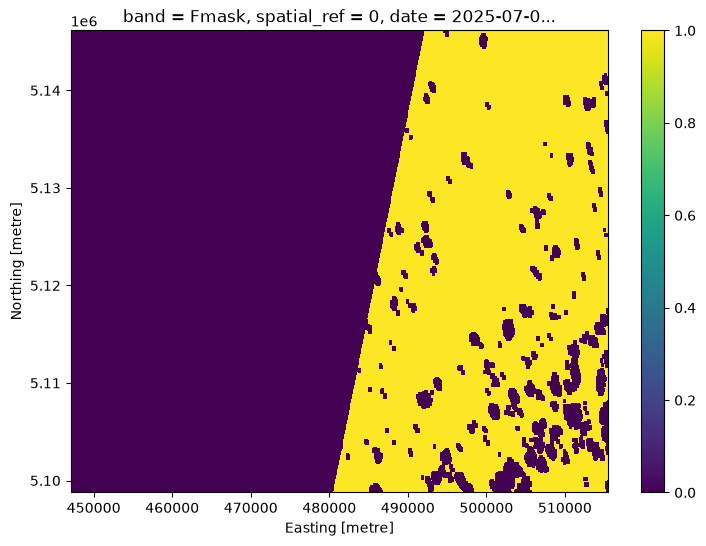

In [14]:
valid_mask_sample = valid_mask.sel(
    x=slice(447063, 515442),
    y=slice(5146127, 5098771),
    method="nearest",
).isel(observation=6)

(
    valid_mask_sample.plot.imshow(
        aspect=valid_mask_sample.shape[1] / valid_mask_sample.shape[0],
        size=6,
    )
)

## Calculate NDVI values for valid observations

Convert the spectral `DataArray` to a `Dataset` for easier band math operations, then use `xr.where` to apply the mask from the previous step. The source reflectance bands remain integer, but the NDVI calculation itself is floating-point math, so this is also the point where the analysis naturally moves from source storage semantics to derived-value semantics.


In [10]:
ds = da.to_dataset(dim="band")

ndvi = (
    ((ds["nir"] - ds["red"]) / (ds["nir"] + ds["red"]))
    .where(
        valid_mask,
    )
    .assign_coords(band="NDVI")
)

ndvi

<xarray.DataArray (observation: 61, y: 37174, x: 17074)> Size: 310GB
dask.array<where, shape=(61, 37174, 17074), dtype=float64, chunksize=(1, 1024, 1024), chunktype=numpy.ndarray>
Coordinates:
  * observation  (observation) int64 488B 0 1 2 3 4 5 6 ... 54 55 56 57 58 59 60
    date         (observation) datetime64[s] 488B 2025-07-01 ... 2025-07-31
    collection   (observation) <U10 2kB 'HLSS30_2.0' ... 'HLSL30_2.0'
  * y            (y) float64 297kB 5.543e+06 5.543e+06 ... 4.428e+06 4.428e+06
  * x            (x) float64 137kB 2.439e+05 2.439e+05 ... 7.561e+05 7.561e+05
    spatial_ref  int64 8B 0
    band         <U4 16B 'NDVI'
Indexes:
  ┌ x        RasterIndex (crs=EPSG:32615)
  └ y

Carve out a spatial subset to visualize so we can inspect the daily NDVI stack more closely without loading the full zone-sized result.

In [11]:
subset = ndvi.sel(
    x=slice(526875, 546171),
    y=slice(5177551, 5164188),
    method="nearest",
)

subset

<xarray.DataArray (observation: 61, y: 447, x: 644)> Size: 140MB
dask.array<getitem, shape=(61, 447, 644), dtype=float64, chunksize=(1, 338, 644), chunktype=numpy.ndarray>
Coordinates:
  * observation  (observation) int64 488B 0 1 2 3 4 5 6 ... 54 55 56 57 58 59 60
    date         (observation) datetime64[s] 488B 2025-07-01 ... 2025-07-31
    collection   (observation) <U10 2kB 'HLSS30_2.0' ... 'HLSL30_2.0'
  * y            (y) float64 4kB 5.178e+06 5.178e+06 ... 5.164e+06 5.164e+06
  * x            (x) float64 5kB 5.269e+05 5.269e+05 ... 5.461e+05 5.462e+05
    spatial_ref  int64 8B 0
    band         <U4 16B 'NDVI'
Indexes:
  ┌ x        RasterIndex (crs=EPSG:32615)
  └ y

In [12]:
_ = await subset.load_async()

/home/henry/workspace/devseed/lazycogs/.venv/lib/python3.13/site-packages/dask/_task_spec.py:768: RuntimeWarning: divide by zero encountered in divide
  return self.func(*new_argspec)
/home/henry/workspace/devseed/lazycogs/.venv/lib/python3.13/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)


Plot the first few observations to see the masked NDVI values. This makes it easier to confirm that cloud and shadow masking removes bad observations while leaving valid pixels untouched.


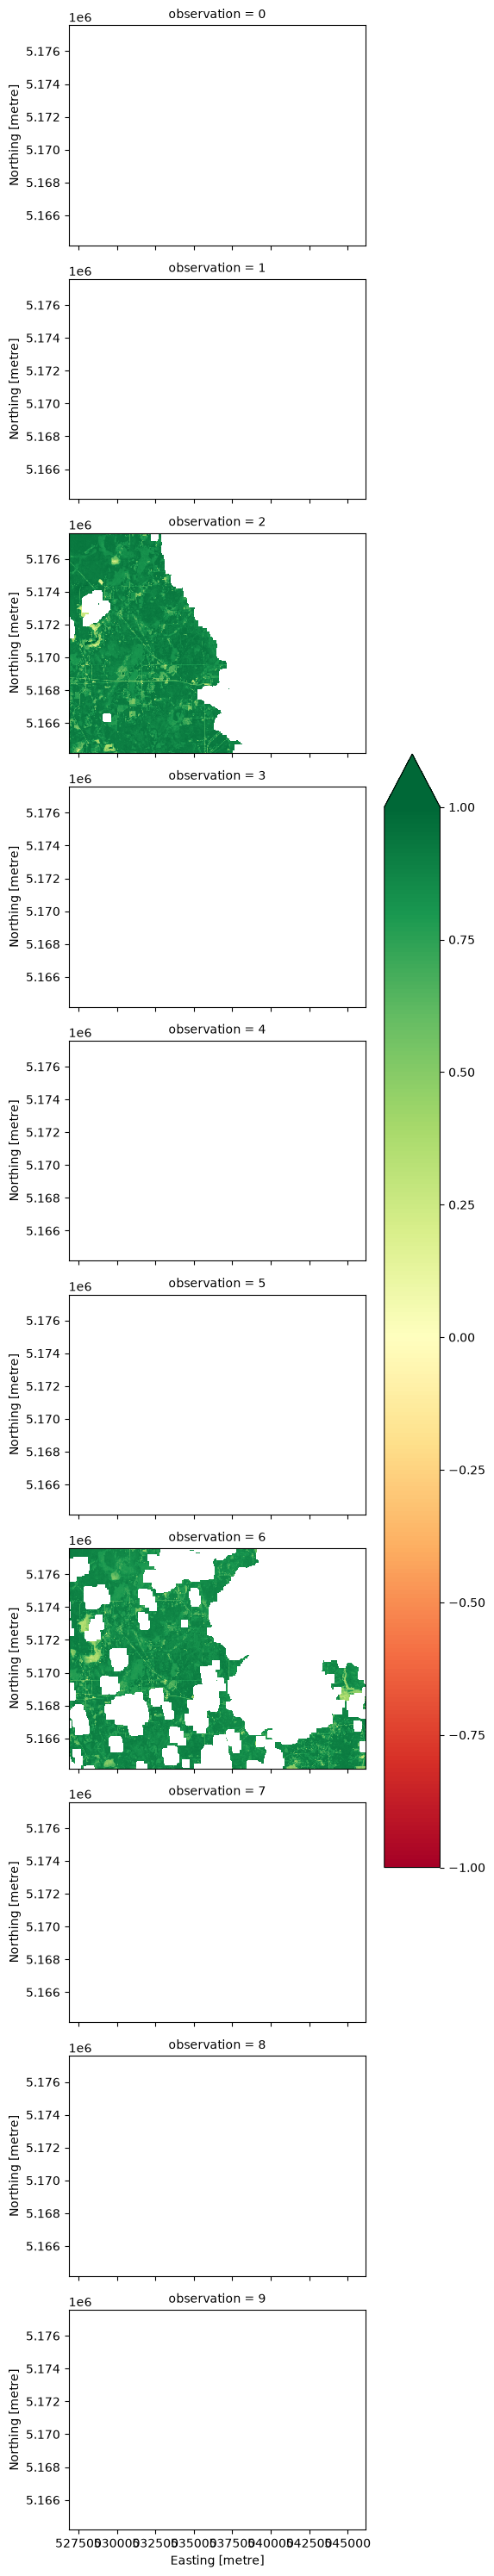

In [13]:
(
    subset.isel(observation=slice(0, 10)).plot.imshow(
        row="observation",
        vmin=-1,
        vmax=1,
        cmap="RdYlGn",
        aspect=subset.shape[2] / subset.shape[1],
    )
)

Calculate the maximum NDVI value for the month of July and plot it. This reduction is useful because it surfaces the strongest cloud-free vegetation signal observed during the month, and correct nodata handling keeps uncovered areas from being mistaken for real low values.

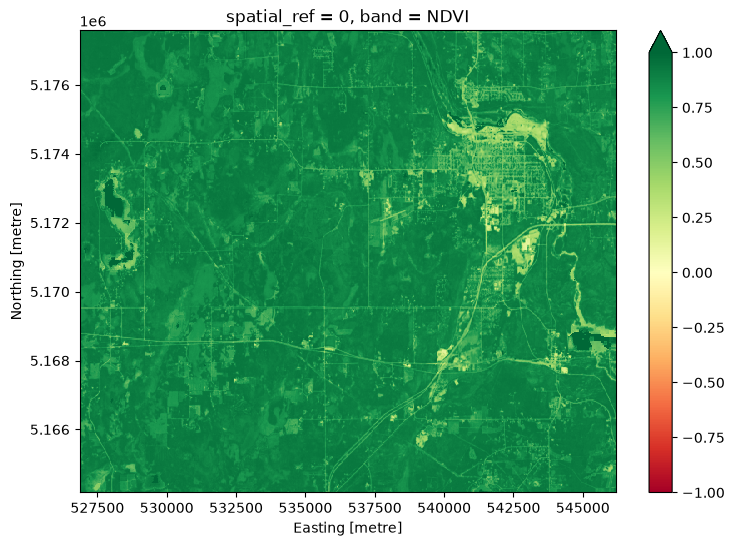

In [15]:
subset.max(dim="observation").plot.imshow(
    vmin=-1,
    vmax=1,
    cmap="RdYlGn",
    aspect=subset.shape[2] / subset.shape[1],
    size=6,
)